# 01 — Data audit
**Project:** Who should be referred for a glucose tolerance test? (see [`docs/problem_definition.md`](../docs/problem_definition.md))

This notebook checks data quality **before** any modelling and records the decisions the modelling stage must follow.

To avoid peeking at the test set, everything below uses the **training split only** (80 %). The test set is created
here with the shared `train_test()` function, and it isn't looked at again until the final evaluation.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

from src.data import (load_raw, mark_missing, train_test, TARGET,
                      ZERO_MEANS_MISSING, NO_LAB_FEATURES, LAB_FEATURES, ALL_FEATURES)

sns.set_theme(style="whitegrid")
raw = load_raw()
train_raw, test_raw = train_test(raw)
train = mark_missing(train_raw)
print(f"Full data: {raw.shape}   train: {train_raw.shape}   test (set aside): {test_raw.shape}")
train_raw.head()

Full data: (768, 9)   train: (614, 9)   test (set aside): (154, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
353,1,90,62,12,43,27.2,0.580,24,0
711,5,126,78,27,22,29.6,0.439,40,0
373,2,105,58,40,94,34.9,0.225,25,0
46,1,146,56,0,0,29.7,0.564,29,0
682,0,95,64,39,105,44.6,0.366,22,0


## 1. Is the data really complete?
The dataset documentation says *"Missing Attribute Values: None"*. But a glucose level, blood pressure, skinfold, insulin or BMI of **0**
is physiologically impossible, so we count zeros per column.

In [2]:
zeros = (train_raw[ALL_FEATURES] == 0).sum().rename("zeros").to_frame()
zeros["share"] = (zeros["zeros"] / len(train_raw)).round(3)
zeros["zero is impossible?"] = zeros.index.isin(ZERO_MEANS_MISSING)
zeros.sort_values("zeros", ascending=False)

,zeros,share,zero is impossible?
Insulin,290,0.472,True
SkinThickness,175,0.285,True
Pregnancies,85,0.138,False
BloodPressure,23,0.037,True
BMI,9,0.015,True
Glucose,4,0.007,True
Age,0,0.000,False
DiabetesPedigree,0,0.000,False


In [3]:
rows_hit = train[ZERO_MEANS_MISSING].isna().any(axis=1)
print(f"Training rows with at least one impossible zero: {rows_hit.sum()} of {len(train)} ({rows_hit.mean():.0%})")

Training rows with at least one impossible zero: 292 of 614 (48%)


- `Pregnancies = 0` is a **valid** value, so we keep those zeros.
- Glucose, BloodPressure, SkinThickness, Insulin and BMI zeros are **missing values in disguise**. From here on they are `NaN`.
- About half the rows are affected, so **dropping incomplete rows is not an option**. It would throw away half the data and
  could bias the sample.

## 2. How are values missing?

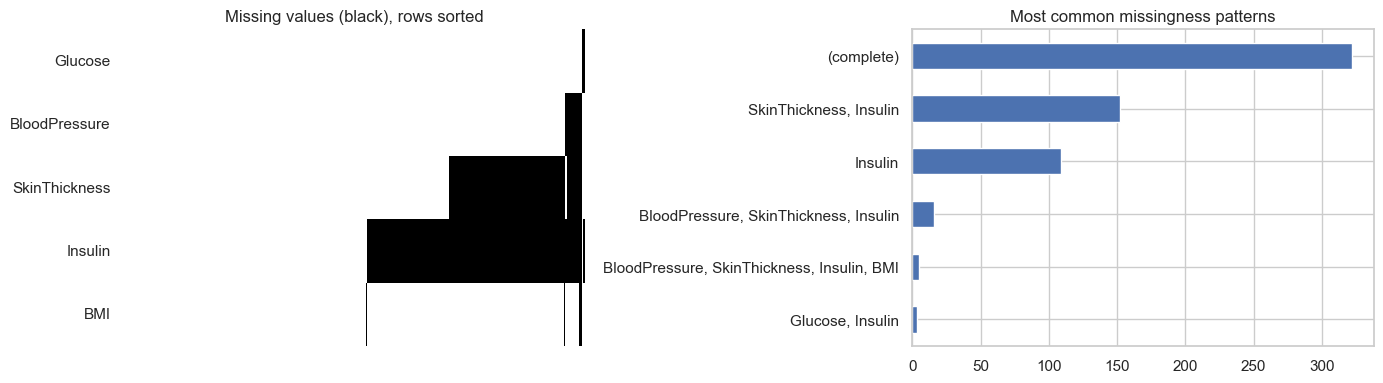

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
miss = train[ZERO_MEANS_MISSING].isna()
sns.heatmap(miss.sort_values(list(miss.columns)).T, cbar=False, ax=axes[0], cmap="Greys")
axes[0].set_title("Missing values (black), rows sorted")
axes[0].set_xticks([])

pattern = miss.apply(lambda r: ", ".join(miss.columns[r]) or "(complete)", axis=1).value_counts().head(6)
pattern.sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Most common missingness patterns")
plt.tight_layout()
plt.show()

- In the training data, **whenever SkinThickness is missing, Insulin is missing too**. Insulin is also missing on its own in many more rows.
- This looks like a measurement protocol (some patients never had these tests), not random recording errors.
- Only about half the training rows are complete.

### 2.1 Is missingness related to the outcome?
If patients with a missing value have a different diabetes rate, then *the fact that a value is missing* carries information.
Simple mean-filling would hide that.

In [5]:
rows = []
for col in ["Insulin", "SkinThickness", "BloodPressure"]:
    is_missing = train[col].isna()
    rows.append({"feature": col,
                 "n missing": int(is_missing.sum()),
                 "diabetes rate if missing": train.loc[is_missing, TARGET].mean(),
                 "diabetes rate if present": train.loc[~is_missing, TARGET].mean()})
pd.DataFrame(rows).set_index("feature").round(3)

,n missing,diabetes rate if missing,diabetes rate if present
feature,,,
Insulin,290,0.362,0.336
SkinThickness,175,0.383,0.335
BloodPressure,23,0.478,0.343


The relationship is **weak**. Diabetes rates differ by only 2–5 percentage points for Insulin and SkinThickness.
BloodPressure shows a bigger gap, but it's based on very few missing rows, so it could easily be noise.
Missing-value indicators are worth *testing* in cross-validation, but we don't expect much from them.

## 3. Class balance

In [6]:
rate = train[TARGET].mean()
print(f"Diabetes rate in training data: {rate:.1%}  ({train[TARGET].sum()} of {len(train)})")
print(f"=> 'predict no diabetes for everyone' gets {1 - rate:.1%} accuracy and catches 0 % of cases.")

Diabetes rate in training data: 34.9%  (214 of 614)
=> 'predict no diabetes for everyone' gets 65.1% accuracy and catches 0 % of cases.


About one in three patients has diabetes. Accuracy would reward a model for ignoring the minority class,
so we use **sensitivity, ROC-AUC and PR-AUC**, as set out in the problem definition.

## 4. Distributions (after treating impossible zeros as missing)

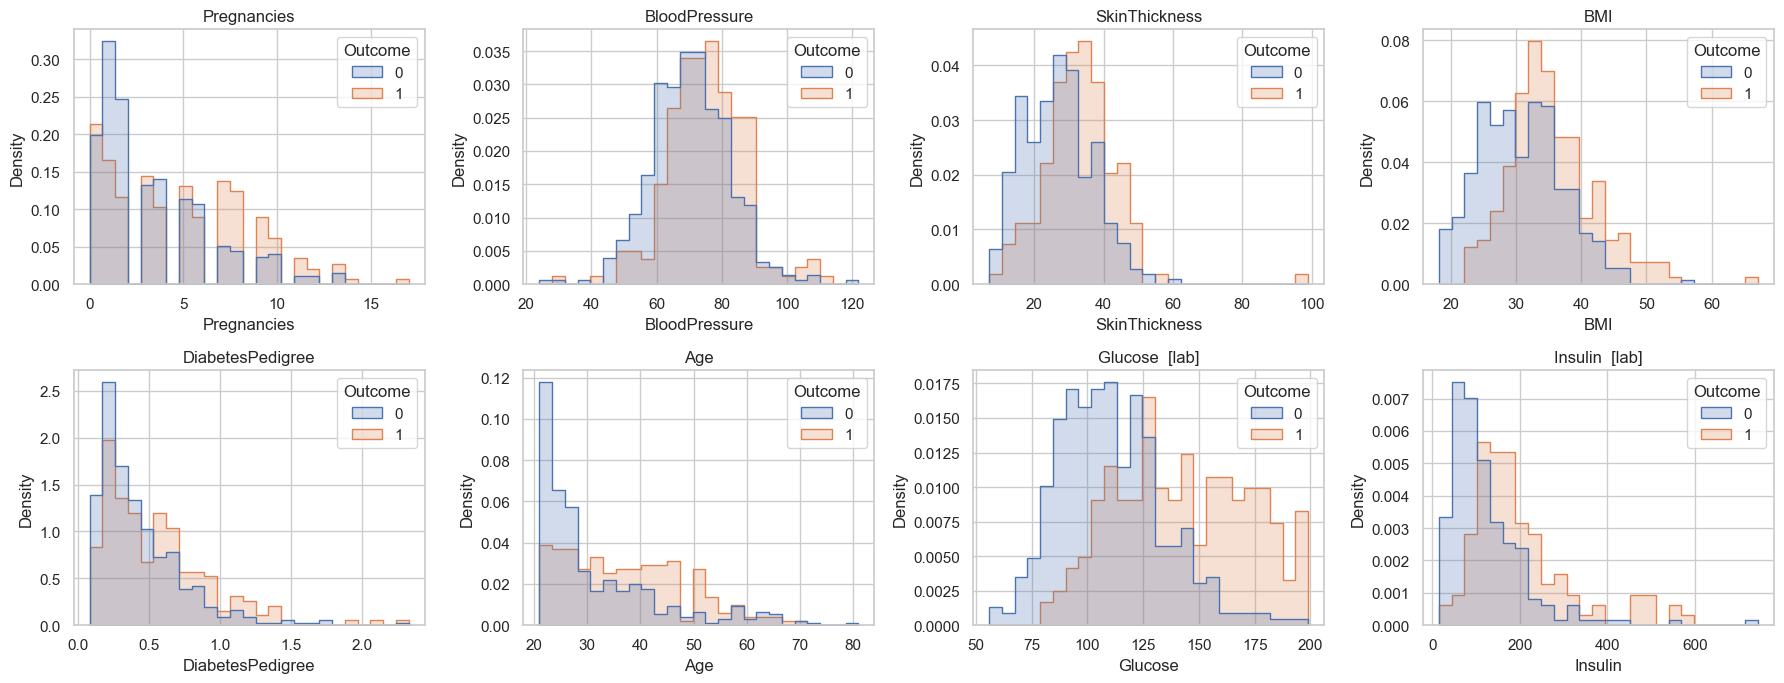

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, ALL_FEATURES):
    sns.histplot(data=train, x=col, hue=TARGET, bins=25, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(col + ("  [lab]" if col in LAB_FEATURES else ""))
plt.tight_layout()
plt.show()

In [8]:
train[ALL_FEATURES].describe().T[["count", "min", "50%", "max"]]

,count,min,50%,max
Pregnancies,614.0,0.000,3.0000,17.000
BloodPressure,591.0,24.000,72.0000,122.000
SkinThickness,439.0,7.000,29.0000,99.000
BMI,605.0,18.200,32.4000,67.100
DiabetesPedigree,614.0,0.084,0.3825,2.329
Age,614.0,21.000,29.0000,81.000
Glucose,610.0,56.000,117.0000,199.000
Insulin,324.0,15.000,125.0000,744.000


- Patients with diabetes have clearly higher **Glucose**, and also higher BMI and Age.
- **Insulin** and **DiabetesPedigree** are strongly right-skewed with long tails, so a few extreme values could dominate a linear model.
  We will try a log transform or robust scaling.
- The extreme values (e.g. insulin in the hundreds, BMI above 60) are rare but **plausible**, so we keep them rather than delete them.

## 5. How much signal does each feature have on its own?
ROC-AUC of each single feature, computed on rows where that feature is present. 0.5 means no signal and 1.0 means perfect ranking.

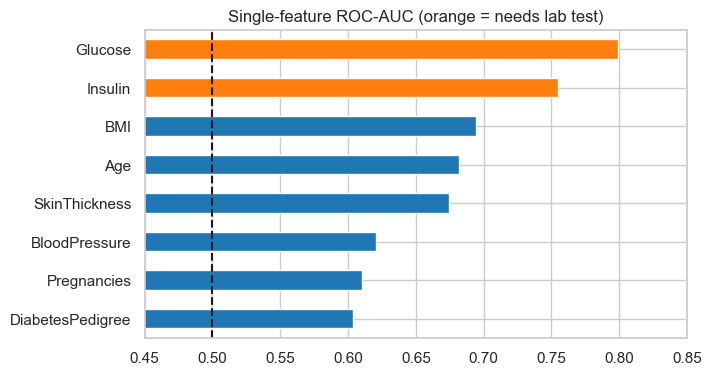

Glucose             0.799
Insulin             0.755
BMI                 0.694
Age                 0.682
SkinThickness       0.675
BloodPressure       0.621
Pregnancies         0.610
DiabetesPedigree    0.604
dtype: float64

In [9]:
auc = {}
for col in ALL_FEATURES:
    present = train[col].notna()
    auc[col] = roc_auc_score(train.loc[present, TARGET], train.loc[present, col])
auc = pd.Series(auc).sort_values()
ax = auc.plot.barh(color=["tab:orange" if c in LAB_FEATURES else "tab:blue" for c in auc.index], figsize=(7, 4))
ax.axvline(0.5, color="k", linestyle="--")
ax.set_xlim(0.45, 0.85)
ax.set_title("Single-feature ROC-AUC (orange = needs lab test)")
plt.show()
auc.round(3).sort_values(ascending=False)

- **Glucose** is the strongest single signal, as expected, because it is the lab test itself.
- **Insulin** looks strong here, but only because we compute it on the rows where it was actually measured.
  If the zeros are left in and treated as real values, its AUC falls to about 0.56. That's a concrete example of why the zero → missing step matters.
- Among no-lab features, **BMI** and **Age** carry the most signal, and none is strong on its own.
  The no-lab model has to *combine* weak signals, so a big jump over the baseline is unlikely.

## 6. Correlations between features

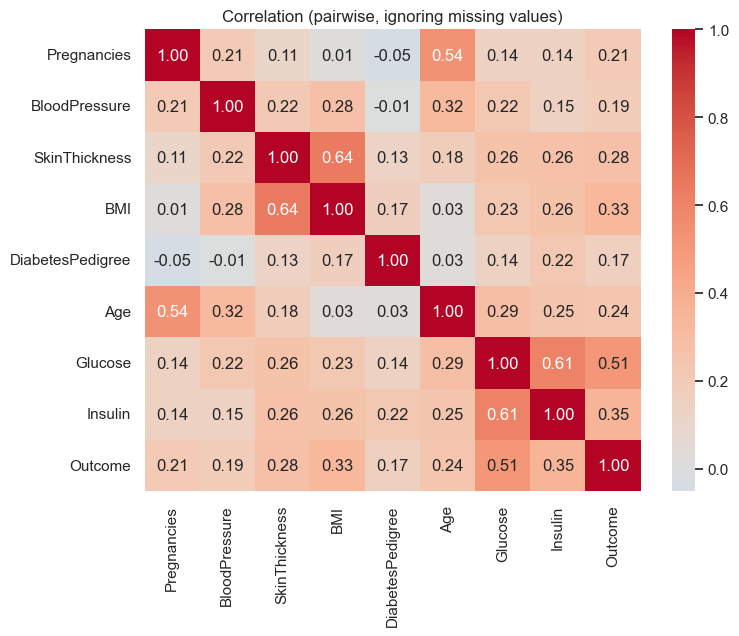

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(train[ALL_FEATURES + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation (pairwise, ignoring missing values)")
plt.show()

## 7. The guideline baseline
The no-lab baseline from the problem definition is to **refer if Age ≥ 35 and BMI ≥ 25**.
Here we only describe what this rule does on the training data. The formal comparison happens on the test set at the end.

In [11]:
refer = (train["Age"] >= 35) & (train["BMI"] >= 25)
caught = (refer & (train[TARGET] == 1)).sum()
print(f"Referral rate: {refer.mean():.1%}")
print(f"Sensitivity:   {caught / train[TARGET].sum():.1%}  (share of diabetes cases referred)")
print(f"Positive rate among referred: {train.loc[refer, TARGET].mean():.1%}  vs  {train[TARGET].mean():.1%} overall")

Referral rate: 32.9%
Sensitivity:   50.9%  (share of diabetes cases referred)
Positive rate among referred: 54.0%  vs  34.9% overall


The rule refers about **one in three** patients but catches only about **half** of the diabetes cases.
That sets the concrete target for the no-lab model: **at a ~33 % referral rate, catch clearly more than ~51 % of cases.**

## 8. Findings and decisions for the modelling stage
*(Numbers refer to the training split. See the outputs above.)*

| # | Finding | Decision |
|---|---|---|
| 1 | Zeros in Glucose, BloodPressure, SkinThickness, Insulin and BMI mean "missing". About half the rows are affected. | Convert them to `NaN` (`src.data.mark_missing`). **Never drop rows.** |
| 2 | Missingness is structured (Skin missing ⇒ Insulin missing), but only weakly related to the outcome. | Impute **inside the CV pipeline** (median first, then try KNN or iterative imputation). Test missing-value indicators, but expect little gain. |
| 3 | About 35 % positive. | Use stratified splits and report sensitivity, ROC-AUC and PR-AUC. Try `class_weight="balanced"`. |
| 4 | Glucose is by far the strongest single feature, but it needs the lab test. | Keep the **two feature sets** separate: no-lab vs full. Compare full against *glucose alone*. |
| 5 | Insulin and Pedigree are heavily skewed. | Try `log1p` or robust scaling for linear models. |
| 6 | The guideline rule refers ~33 % of patients and catches only ~51 % of cases. | The no-lab model must catch more cases **at the same referral rate**. |
| 6b | Insulin is only informative once zeros are treated as missing (AUC ~0.56 → ~0.75). | Keep the zero → NaN step in every pipeline, including the app. |
| 7 | Small data (614 training rows). | Use **repeated** stratified CV and bootstrap confidence intervals, and prefer simpler models unless complex ones clearly win. |